# Multi-session registration

Registers CNMF-E results (`*_caiman.hdf5` from `caiman-cnmfe`) of a set of recordings, in temporal order,
using CaImAn's `register_multisession`. 

1. Read `session_metadata.csv` (one row per recording) and check that every (recording, e-focus) has a CaImAn result + timestamps
2. Pick the best e-focus plane per recording (by number of accepted components, median SNR, or their product) → table `best_planes`
3. Select rows of `best_planes` to register (`SELECTION`), register, inspect matches and matched traces
4. Save one HDF5 with all traces indexed by a common **union cell id** (+ an assignments CSV)

## 1. Setup

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from caiman_tools import multisession as ms
from caiman_tools.logging_utils import setup_logging

%matplotlib widget
pd.set_option("display.width", 200, "display.max_columns", 30)
setup_logging("NONE")  # CaImAn's internal logging off; caiman_tools messages shown

## 2. Configuration

In [ ]:
METADATA_CSV = Path(
    "/nfs/scistore19/jonasgrp/sbhattac/MiniCA3_pilot/Outputs_pilot/session_metadata.csv"
)
OUT_DIR = (
    METADATA_CSV.parent / "registered"
)  # <animal>_<first date>_to_<last date>_registered.h5

## 3. Check which CaImAn results exist and consolidate sessions table

One row per (recording, e-focus). `status` must be `ok` for a plane to be used.
`fr_mismatch` flags results whose CNMF-E `fr` parameter differs from the actual per-plane frame rate (from the timestamps):
multi-plane recordings are interleaved, so each plane runs at acquisition rate / number of planes.

In [13]:
sessions = ms.load_session_table(METADATA_CSV)
sessions_planes = ms.add_plane_stats(ms.find_plane_results(sessions))

cols = [
    "animal_id",
    "date",
    "recording",
    "efocus",
    "status",
    "n_total",
    "n_accepted",
    "snr_median",
    "n_snr_inf",
    "T",
    "fr_params",
    "fr_timestamps",
    "fr_mismatch",
]

for r in sessions_planes[sessions_planes.status != "ok"].itertuples():
    print(f"[{r.status}] {r.recording} e-focus {r.efocus}")
for r in sessions_planes[sessions_planes.fr_mismatch == True].itertuples():
    print(
        f"[fr mismatch] {r.recording} e-focus {r.efocus}: processed with fr={r.fr_params:g}, "
        f"actual {r.fr_timestamps:.2f} Hz"
    )

sessions_planes[cols]

,animal_id,date,recording,efocus,status,n_total,n_accepted,snr_median,n_snr_inf,T,fr_params,fr_timestamps,fr_mismatch
0,5133,2026-06-12,SB_PJ_2026-06-12-11-13-05_video_trig_0,580,ok,36,36,7.139670,0,11998,10.0,9.998794,False
1,5133,2026-06-12,SB_PJ_2026-06-12-11-13-05_video_trig_0,680,ok,25,25,7.080168,0,11998,10.0,9.998794,False
2,5133,2026-06-12,SB_PJ_2026-06-12-11-13-05_video_trig_0,780,ok,10,10,7.075142,0,11998,10.0,9.998794,False
3,5133,2026-06-12,SB_PJ_2026-06-12-14-25-41_video_trig_0,580,ok,14,14,8.819404,0,17997,10.0,9.998794,False
4,5133,2026-06-12,SB_PJ_2026-06-12-14-25-41_video_trig_0,680,ok,21,21,7.756582,0,17998,10.0,9.998794,False
5,5133,2026-06-12,SB_PJ_2026-06-12-14-25-41_video_trig_0,780,ok,13,13,7.312340,0,17997,10.0,9.998794,False
6,5133,2026-06-24,SB_PJ_2026-06-24-12-35-41_video_trig_0,580,ok,38,38,8.508825,0,17997,10.0,9.998794,False
7,5133,2026-06-24,SB_PJ_2026-06-24-12-35-41_video_trig_0,680,ok,24,23,9.523040,0,17998,10.0,9.998794,False
8,5133,2026-06-24,SB_PJ_2026-06-24-12-35-41_video_trig_0,780,ok,11,11,9.054184,0,17998,10.0,9.998794,False
9,5133,2026-06-24,SB_PJ_2026-06-24-15-57-23_video_trig_0,580,ok,28,27,8.358830,0,17997,10.0,9.998794,False


## 4. Best e-focus plane per recording

For each recording, keep the e-focus with the highest `CRITERION`:

* `"n_accepted"`: number of accepted components
* `"snr_median"`: median SNR of the accepted components
* `"n_x_snr"`: `n_accepted × snr_median` (many cells *and* good SNR)

Single-plane recordings have only one option, so this only matters for the multi-plane ones.
The result, `best_planes`, has one row per recording; its index is what you select from in the next step.

In [14]:
CRITERION = "n_x_snr"  # or "snr_median", "n_x_snr", or "n_accepted"

sessions_planes["n_x_snr"] = sessions_planes.n_accepted * sessions_planes.snr_median
ok = sessions_planes[sessions_planes.status == "ok"]


# Per recording, keep the e-focus with the highest criterion
best_planes = (
    ok.loc[ok[CRITERION].fillna(0).groupby(ok.recording).idxmax()]
    .sort_values(["animal_id", "start_time"])
    .reset_index(drop=True)
)

best_planes[
    [
        "animal_id",
        "start_time",
        "recording",
        "efocus",
        "n_accepted",
        "snr_median",
        "n_x_snr",
    ]
]

,animal_id,start_time,recording,efocus,n_accepted,snr_median,n_x_snr
0,5133,2026-06-12 11:13:05,SB_PJ_2026-06-12-11-13-05_video_trig_0,580,36,7.139670,257.028113
1,5133,2026-06-12 14:25:41,SB_PJ_2026-06-12-14-25-41_video_trig_0,680,21,7.756582,162.888216
2,5133,2026-06-24 12:35:41,SB_PJ_2026-06-24-12-35-41_video_trig_0,580,38,8.508825,323.335333
3,5133,2026-06-24 15:57:23,SB_PJ_2026-06-24-15-57-23_video_trig_0,580,27,8.358830,225.688404
4,5133,2026-09-28 16:51:13,SB_PJ_2026-09-28-16-51-13_video_trig_0,580,67,6.512497,436.337307
5,5133,2026-10-22 18:04:26,SB_PJ_2026-10-22-18-04-26_video_trig_0,580,54,6.937017,374.598944
6,544370,2026-06-25 12:47:45,SB_PJ_2026-06-25-12-47-45_video_trig_0,320,55,8.134353,447.389408
7,583,2026-09-15 17:32:26,SB_PJ_2026-09-15-17-32-26_video_trig_0,660,24,4.958558,119.005398
8,583,2026-10-01 16:27:02,SB_PJ_2026-10-01-16-27-02_video_trig_0,660,8,5.747715,45.981724
9,583,2026-10-22 16:57:04,SB_PJ_2026-10-22-16-57-04_video_trig_0,660,0,NaN,NaN


## 5. Select sessions to register

List the `best_planes` indices to register. They are registered in **temporal order** (whatever order you list them in).
Sessions without accepted components are dropped automatically.

In [15]:
SELECTION = [0, 1, 2, 3, 4]  # indices into best_planes

selection = best_planes.loc[SELECTION].sort_values("start_time")
if selection.animal_id.nunique() > 1:
    print(
        f"WARNING: selection contains several animals: {sorted(selection.animal_id.unique())}"
    )
for r in selection[selection.n_accepted == 0].itertuples():
    print(f"NOTE: {r.recording} has no accepted components and will be dropped")
selection[
    [
        "animal_id",
        "start_time",
        "recording",
        "efocus",
        "n_accepted",
        "snr_median",
        "n_x_snr",
    ]
]

,animal_id,start_time,recording,efocus,n_accepted,snr_median,n_x_snr
0,5133,2026-06-12 11:13:05,SB_PJ_2026-06-12-11-13-05_video_trig_0,580,36,7.139670,257.028113
1,5133,2026-06-12 14:25:41,SB_PJ_2026-06-12-14-25-41_video_trig_0,680,21,7.756582,162.888216
2,5133,2026-06-24 12:35:41,SB_PJ_2026-06-24-12-35-41_video_trig_0,580,38,8.508825,323.335333
3,5133,2026-06-24 15:57:23,SB_PJ_2026-06-24-15-57-23_video_trig_0,580,27,8.358830,225.688404
4,5133,2026-09-28 16:51:13,SB_PJ_2026-09-28-16-51-13_video_trig_0,580,67,6.512497,436.337307


## 6. Register

Registration parameters (see `caiman.base.rois.register_multisession`):
* `thresh_cost` - max matching cost (1 − Jaccard overlap of binarised footprints); lower = stricter
* `max_dist` - max centroid distance (px) for a candidate match
* `max_thr` - footprint binarisation threshold (fraction of max)
* `align_flag`, `use_opt_flow` - align the templates (correlation images) before matching (rigid + optical flow)

Registration is sequential: session 0 → 1, then the union → 2, and so on.

In [16]:
REG_PARAMS = {
    "thresh_cost": 0.7,
    "max_dist": 10,
    "max_thr": 0,
    "align_flag": True,
    "use_opt_flow": True,
}

reg_sessions = [ms.load_session(r) for r in selection.itertuples()]
for s in reg_sessions:
    print(
        f"{s.start_time:%Y-%m-%d %H:%M} ef{s.efocus}: {s.A.shape[1]} accepted, "
        f"T={s.traces['F_dff'].shape[1] if 'F_dff' in s.traces else 0}, {s.fr:.1f} Hz  {s.recording}"
    )

2026-06-12 11:13 ef580: 36 accepted, T=11998, 10.0 Hz  SB_PJ_2026-06-12-11-13-05_video_trig_0
2026-06-12 14:25 ef680: 21 accepted, T=17998, 10.0 Hz  SB_PJ_2026-06-12-14-25-41_video_trig_0
2026-06-24 12:35 ef580: 38 accepted, T=17997, 10.0 Hz  SB_PJ_2026-06-24-12-35-41_video_trig_0
2026-06-24 15:57 ef580: 27 accepted, T=17997, 10.0 Hz  SB_PJ_2026-06-24-15-57-23_video_trig_0
2026-09-28 16:51 ef580: 67 accepted, T=53990, 30.0 Hz  SB_PJ_2026-09-28-16-51-13_video_trig_0


5133_2026-06-12_to_2026-09-28


,n_cells
found in n sessions,
1,53
2,11
3,15
4,6
5,9


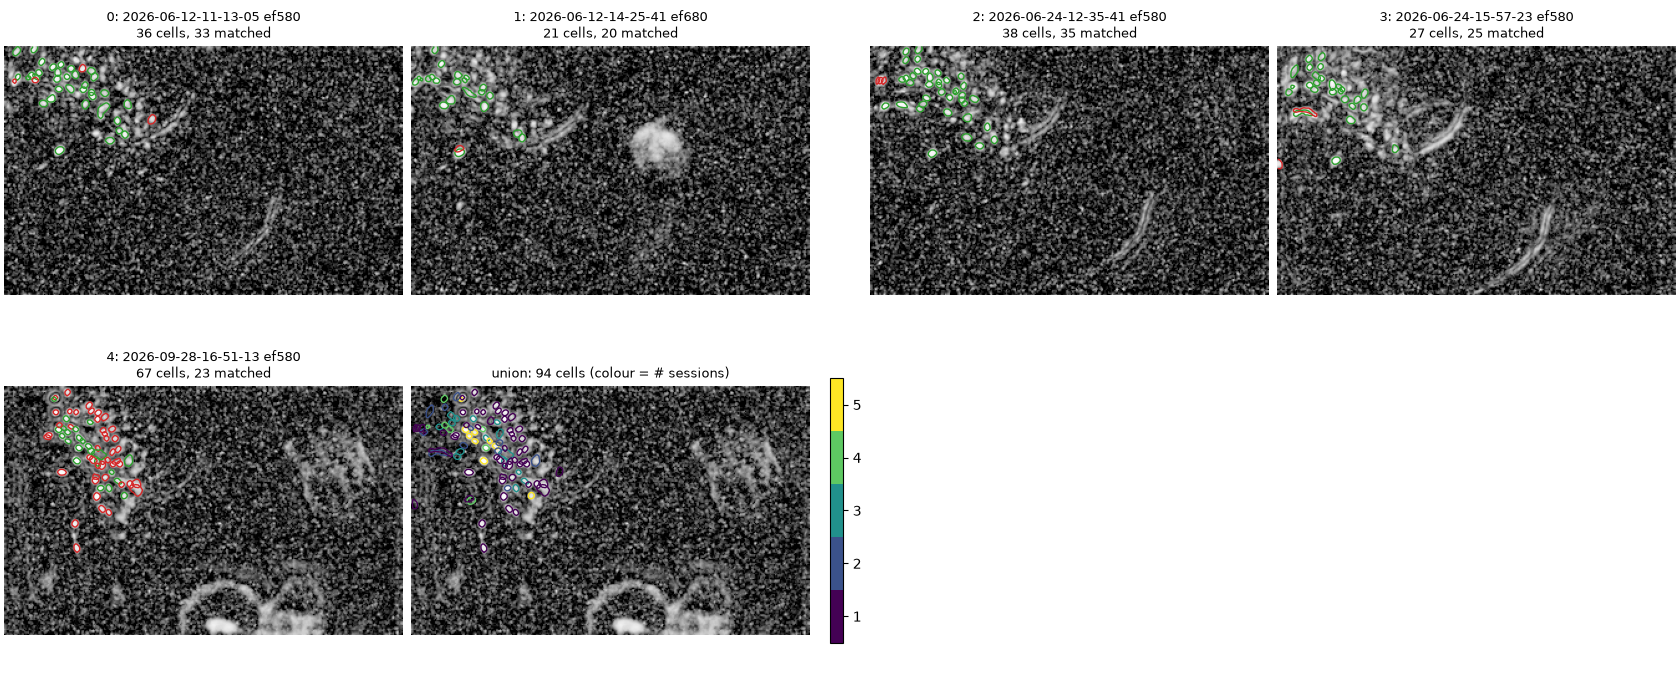

In [17]:
reg = ms.register_sessions(reg_sessions, **REG_PARAMS)
print(reg.name)
ms.plot_registration(reg)
reg.summary()

In [19]:
# Full mapping: union cell id -> original CaImAn component index per session (-1 = not found)
reg.assignment_table()

,SB_PJ_2026-06-12-11-13-05_video_trig_0,SB_PJ_2026-06-12-14-25-41_video_trig_0,SB_PJ_2026-06-24-12-35-41_video_trig_0,SB_PJ_2026-06-24-15-57-23_video_trig_0,SB_PJ_2026-09-28-16-51-13_video_trig_0,n_present
union_id,,,,,,
0,0,10,7,15,11,5
1,1,14,17,4,16,5
2,2,15,1,-1,-1,3
3,3,12,31,8,27,5
4,4,4,22,-1,-1,3
...,...,...,...,...,...,...
89,-1,-1,-1,-1,64,1
90,-1,-1,-1,-1,65,1
91,-1,-1,-1,-1,66,1


### Matched traces

Cells found in all sessions; sessions are shown back to back in temporal order (time within each session).

9 cells in all 5 sessions


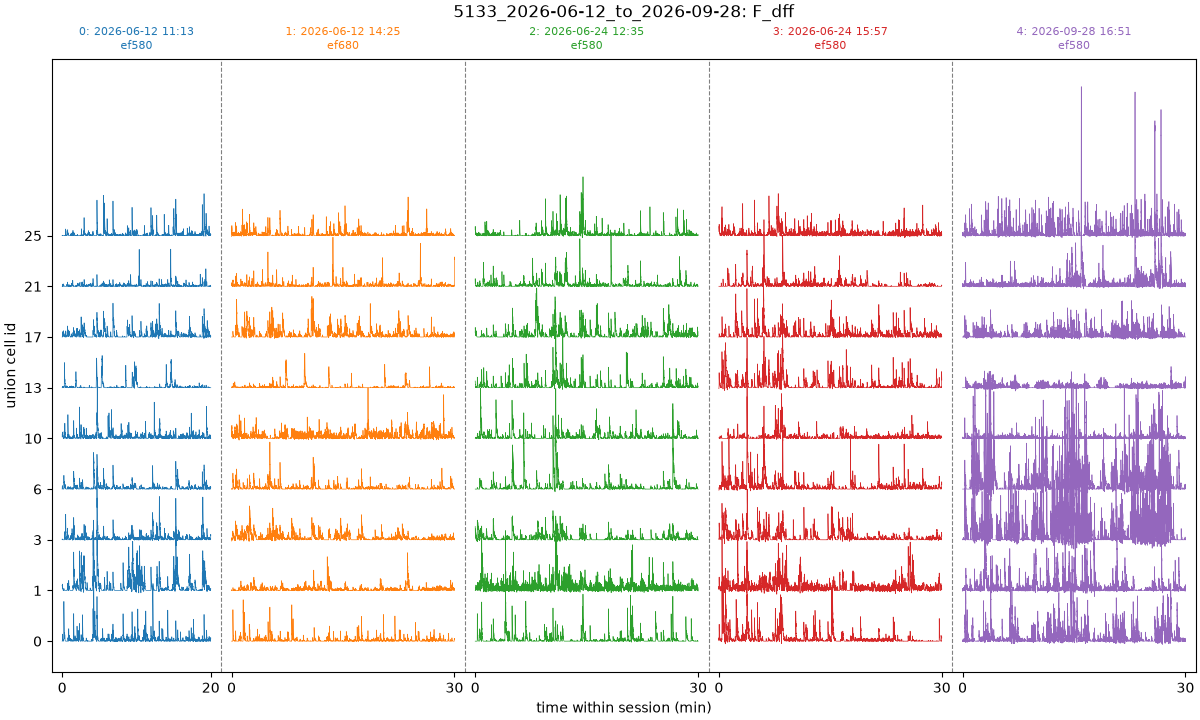

In [21]:
TRACE = "F_dff"  # "F_dff" (detrended dF/F), "C" (denoised), "S_dff" (deconvolved)
in_all = np.flatnonzero(reg.n_present == len(reg.sessions))
print(f"{len(in_all)} cells in all {len(reg.sessions)} sessions")
ms.plot_matched_traces(reg, in_all[:15], name=TRACE, spacing=None);

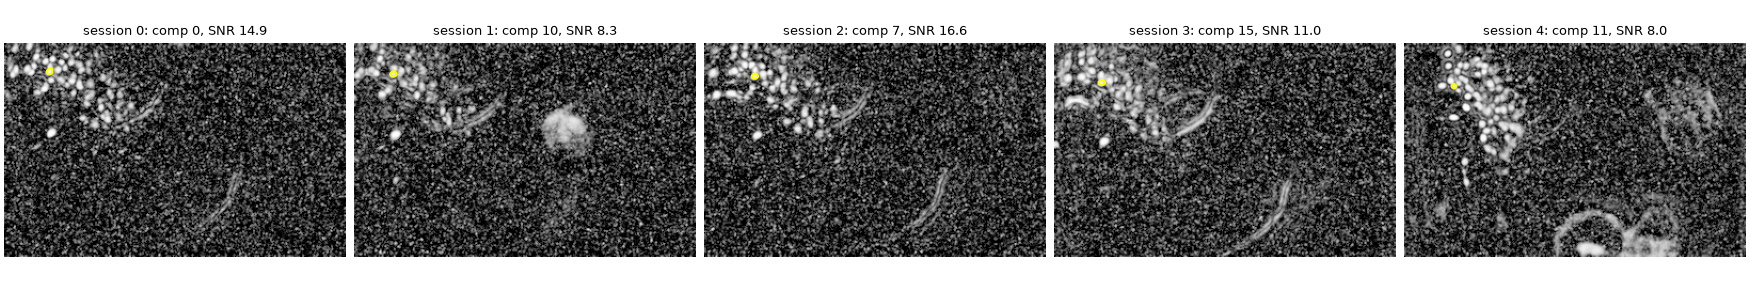

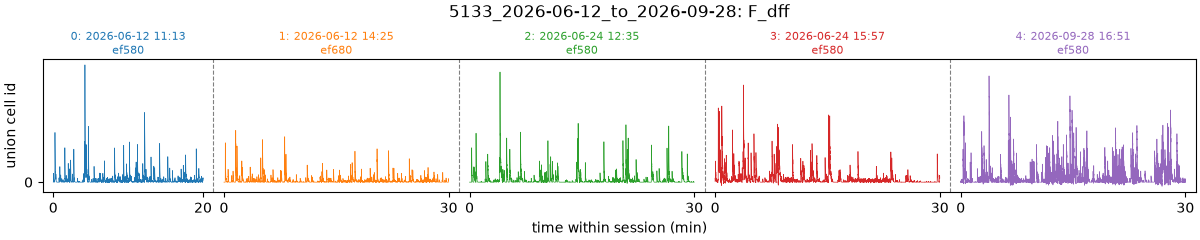

In [22]:
# Inspect one union cell: footprint per session + traces
CELL = int(in_all[0]) if len(in_all) else 0

fig, axs = plt.subplots(
    1, len(reg.sessions), figsize=(3.5 * len(reg.sessions), 3), constrained_layout=True
)
for j, (ax, s) in enumerate(zip(np.atleast_1d(axs), reg.sessions)):
    ax.imshow(s.Cn, cmap="gray")
    k = reg.assignments[CELL, j]
    if not np.isnan(k):
        fp = s.A[:, int(k)].toarray().reshape(reg.dims, order="F")
        ax.contour(fp, levels=[0.5 * fp.max()], colors="yellow")
        ax.set_title(
            f"session {j}: comp {s.idx_accepted[int(k)]}, SNR {s.snr[int(k)]:.1f}",
            fontsize=9,
        )
    else:
        ax.set_title(f"session {j}: not found", fontsize=9)
    ax.axis("off")
ms.plot_matched_traces(reg, [CELL], name=TRACE);

## 7. Save

`<animal>_<first date>_to_<last date>_registered.h5` (name: `reg.name`): every trace array is `(n_union, T_session)` with **row = union cell id** (NaN where a cell was not found),
so `F_dff` of union cell `i` in session `k` is `sessions/k/F_dff[i]`. Plus `_assignments.csv` (union id → original CaImAn component index per session, for going back to the `_caiman.hdf5`).



In [23]:
h5_path, csv_path = ms.save_registered(reg, OUT_DIR)

loaded = ms.load_registered(h5_path)
print({k: v for k, v in loaded.items() if k not in ("union", "sessions")})
print([(s["recording"], s["F_dff"].shape) for s in loaded["sessions"]])

16:38:01 | INFO     | caiman_tools.multisession - Wrote 5133_2026-06-12_to_2026-09-28_registered.h5 and 5133_2026-06-12_to_2026-09-28_registered_assignments.csv


{'animal_ids': array(['5133', '5133', '5133', '5133', '5133'], dtype=object), 'efoci': array([580, 680, 580, 580, 580]), 'n_sessions': np.int64(5), 'n_union': np.int64(94), 'name': '5133_2026-06-12_to_2026-09-28', 'recordings': array(['SB_PJ_2026-06-12-11-13-05_video_trig_0',
       'SB_PJ_2026-06-12-14-25-41_video_trig_0',
       'SB_PJ_2026-06-24-12-35-41_video_trig_0',
       'SB_PJ_2026-06-24-15-57-23_video_trig_0',
       'SB_PJ_2026-09-28-16-51-13_video_trig_0'], dtype=object), 'registration_params': '{"thresh_cost": 0.7, "max_dist": 10, "max_thr": 0, "align_flag": true, "use_opt_flow": true, "enclosed_thr": null}', 'start_times': array(['2026-06-12 11:13:05', '2026-06-12 14:25:41',
       '2026-06-24 12:35:41', '2026-06-24 15:57:23',
       '2026-09-28 16:51:13'], dtype=object)}
[('SB_PJ_2026-06-12-11-13-05_video_trig_0', (94, 11998)), ('SB_PJ_2026-06-12-14-25-41_video_trig_0', (94, 17998)), ('SB_PJ_2026-06-24-12-35-41_video_trig_0', (94, 17997)), ('SB_PJ_2026-06-24-15-57-23_vid